In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("winequality-red.csv",sep = ";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [7]:
print('Shape:', df.shape)
df.info()
df.describe().T

Shape: (1599, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [8]:
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df['quality'].value_counts().sort_index()

Missing values: 0
Duplicate rows: 240


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

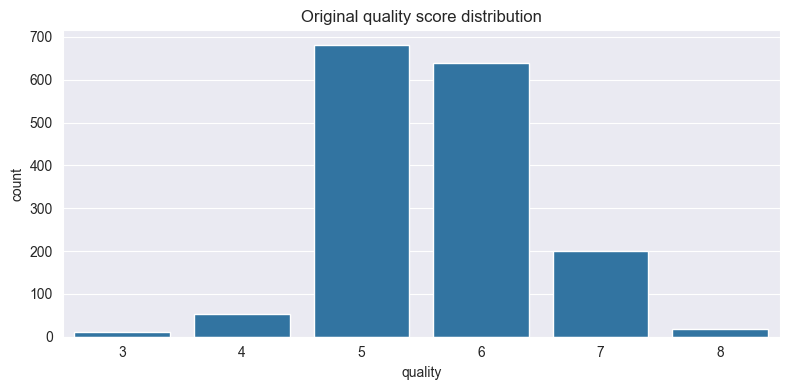

In [9]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='quality')
plt.title('Original quality score distribution')
plt.tight_layout()

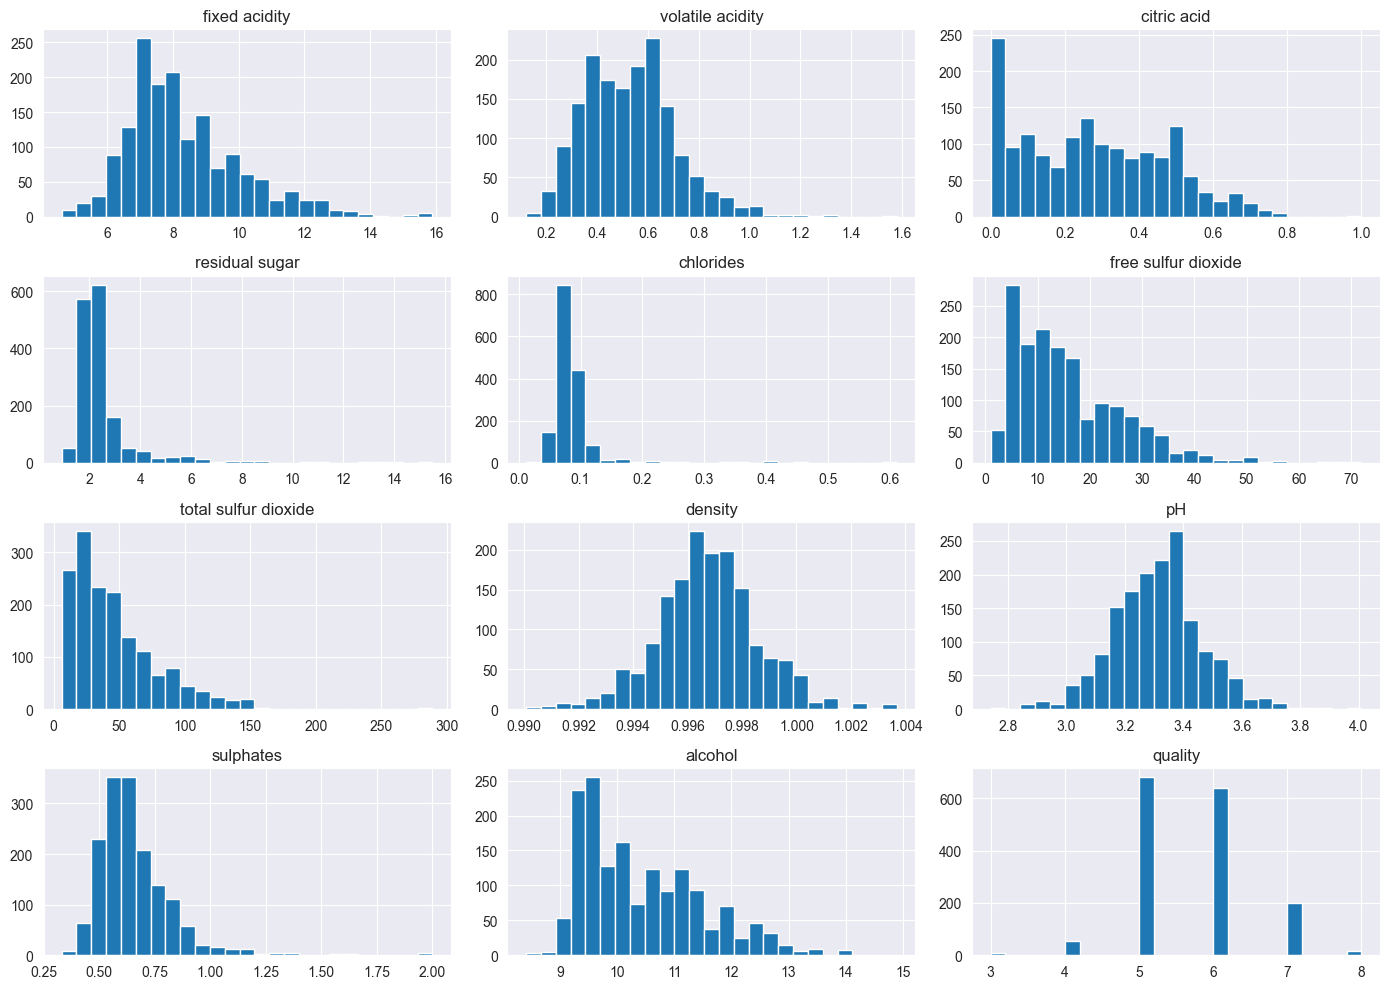

In [10]:
df.hist(figsize=(14,10), bins=25)
plt.tight_layout()

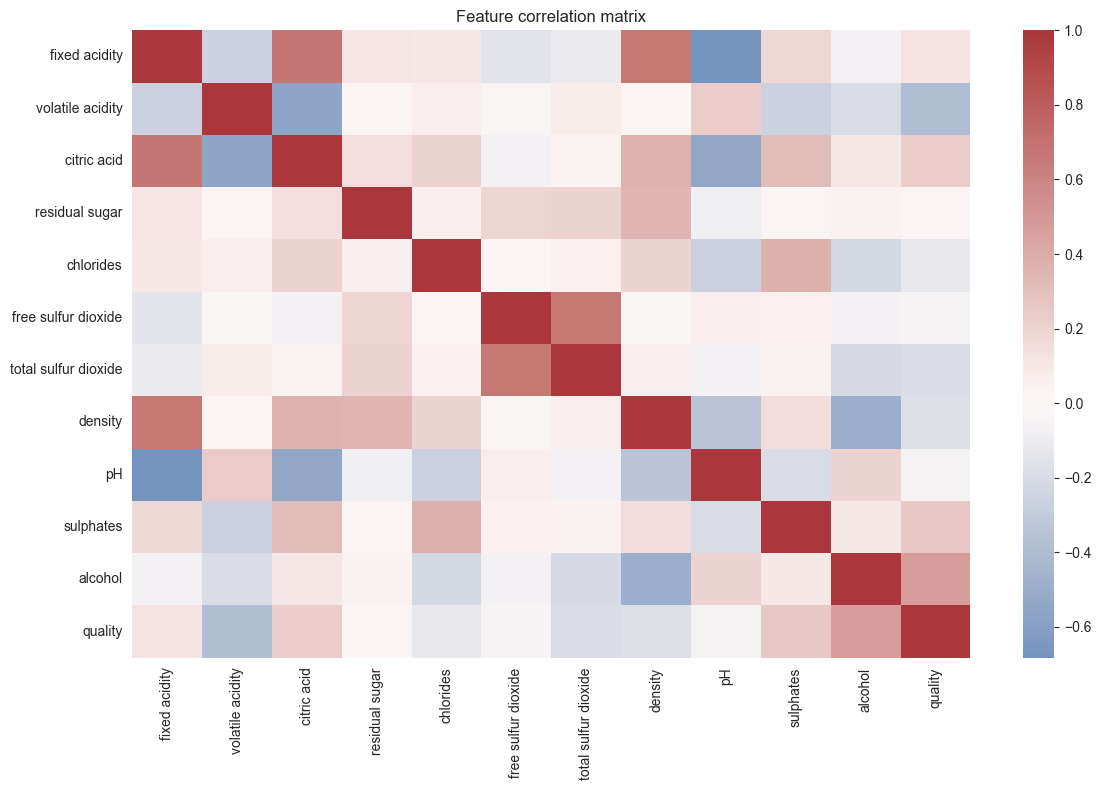

In [11]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), cmap='vlag', center=0)
plt.title('Feature correlation matrix')
plt.tight_layout()

In [12]:
df['quality_class'] = (df['quality'] >= 6).astype(int)
X = df.drop(columns=['quality', 'quality_class'])
y = df['quality_class']
print(y.value_counts(normalize=True).rename('fraction'))

quality_class
1    0.534709
0    0.465291
Name: fraction, dtype: float64


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5,
                              class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
print('Train accuracy:', model.score(X_train, y_train))
print('Test accuracy:', model.score(X_test, y_test))

Train accuracy: 0.7732603596559813
Test accuracy: 0.7375


In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, RocCurveDisplay)

prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
print('Accuracy :', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred, zero_division=0))
print('Recall   :', recall_score(y_test, pred, zero_division=0))
print('F1       :', f1_score(y_test, pred, zero_division=0))
print('ROC-AUC  :', roc_auc_score(y_test, prob))
print(classification_report(y_test, pred, zero_division=0))

Accuracy : 0.7375
Precision: 0.7636363636363637
Recall   : 0.7368421052631579
F1       : 0.75
ROC-AUC  : 0.7776207857451234
              precision    recall  f1-score   support

           0       0.71      0.74      0.72       149
           1       0.76      0.74      0.75       171

    accuracy                           0.74       320
   macro avg       0.74      0.74      0.74       320
weighted avg       0.74      0.74      0.74       320



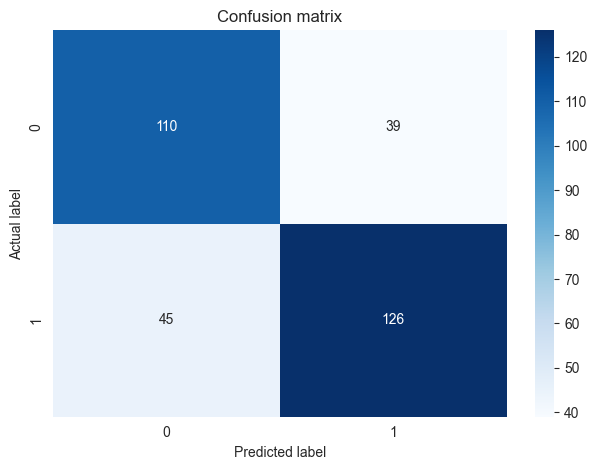

In [15]:
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Confusion matrix')
plt.tight_layout()

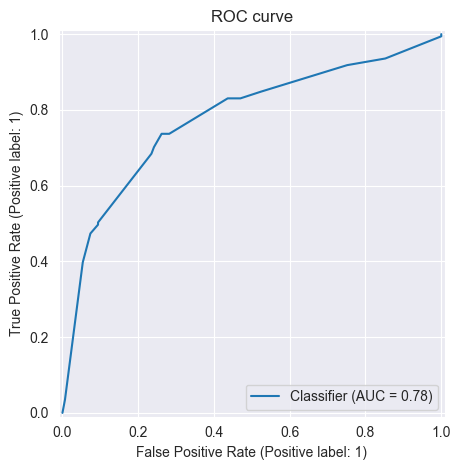

In [16]:
RocCurveDisplay.from_predictions(y_test, prob)
plt.title('ROC curve')
plt.tight_layout()

In [17]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance

alcohol                 0.549495
sulphates               0.217286
total sulfur dioxide    0.114105
volatile acidity        0.072768
pH                      0.026657
chlorides               0.019690
fixed acidity           0.000000
citric acid             0.000000
residual sugar          0.000000
free sulfur dioxide     0.000000
density                 0.000000
dtype: float64

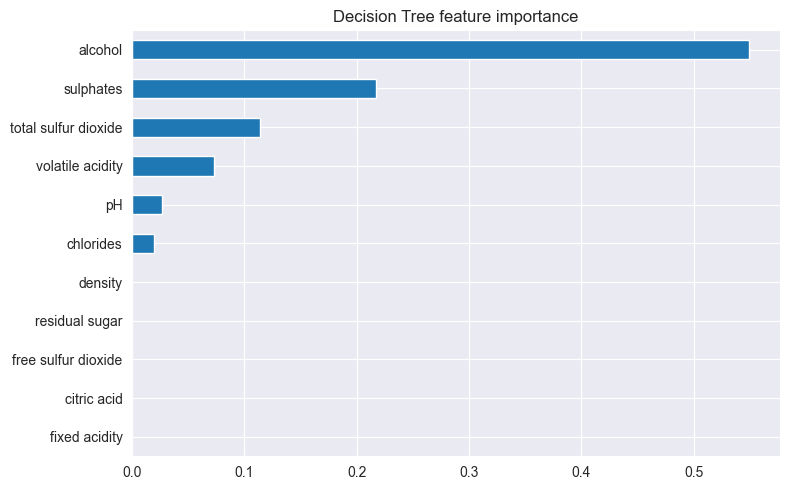

In [18]:
importance.sort_values().plot(kind='barh', figsize=(8,5))
plt.title('Decision Tree feature importance')
plt.tight_layout()

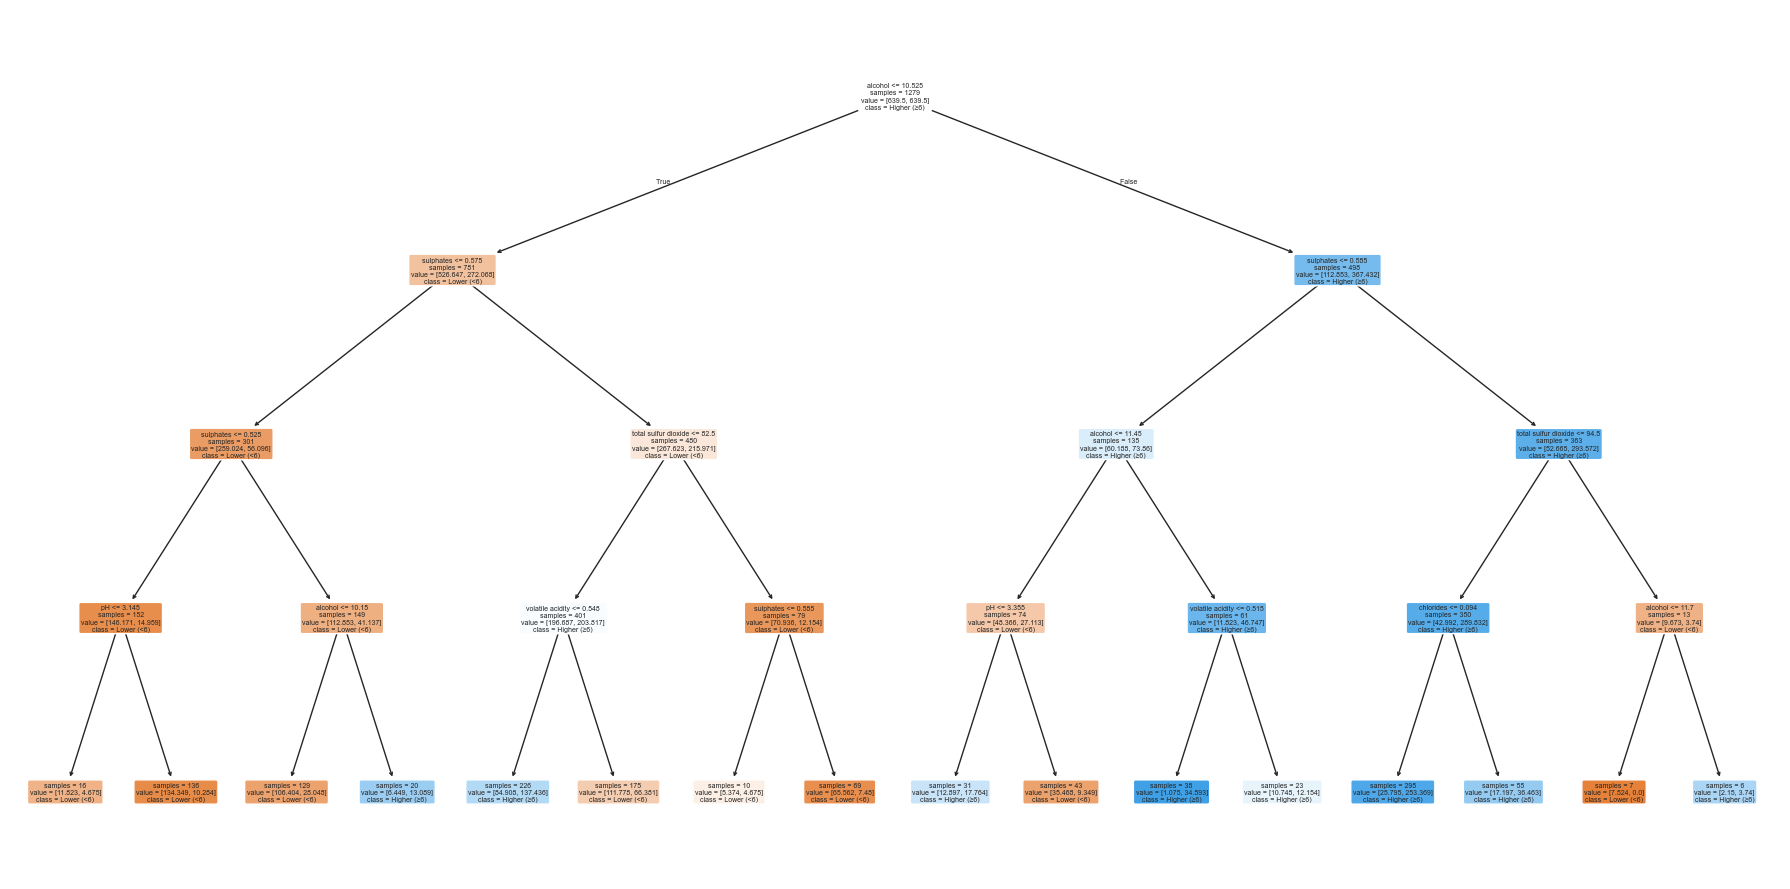

In [20]:
from sklearn.tree import plot_tree
plt.figure(figsize=(18,9))
plot_tree(model, feature_names=X.columns, class_names=['Lower (<6)', 'Higher (≥6)'],
          filled=True, rounded=True, impurity=False)
plt.tight_layout()

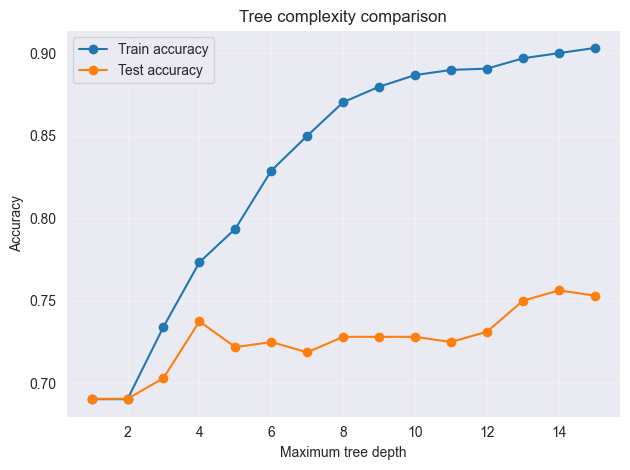

In [21]:
depths = range(1, 16)
train_scores, test_scores = [], []
for d in depths:
    candidate = DecisionTreeClassifier(max_depth=d, min_samples_leaf=5,
                                      class_weight='balanced', random_state=42)
    candidate.fit(X_train, y_train)
    train_scores.append(candidate.score(X_train, y_train))
    test_scores.append(candidate.score(X_test, y_test))

plt.plot(depths, train_scores, marker='o', label='Train accuracy')
plt.plot(depths, test_scores, marker='o', label='Test accuracy')
plt.xlabel('Maximum tree depth')
plt.ylabel('Accuracy')
plt.title('Tree complexity comparison')
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()